# Which Channel and Store Drive Revenue?

In [1]:
from pathlib import Path

project_root = Path.cwd().parent
data_dir = project_root / "data" / "raw"

In [2]:
import sys
sys.path.append('..')
from src.bookstore_health_analysis.data_loader import load_all_data

dfs = load_all_data(data_dir)

In [3]:
sales = dfs['bookstore_sales']

channel_monthly = (
    sales.groupby([sales['date'].dt.to_period('M'), 'channel'])['revenue']
    .sum()
    .reset_index()
)

channel_monthly

,date,channel,revenue
0,2019-01,IN_STORE,144784.68
1,2019-01,ONLINE,14924.37
2,2019-02,IN_STORE,145224.18
3,2019-02,ONLINE,15042.75
4,2019-03,IN_STORE,177796.08
...,...,...,...
139,2024-10,ONLINE,35091.37
140,2024-11,IN_STORE,210100.65
141,2024-11,ONLINE,38596.22
142,2024-12,IN_STORE,255316.06


In [5]:
store_monthly = (
    sales.groupby([sales['date'].dt.to_period('M'), 'store_id'])['revenue']
    .sum()
    .reset_index()
)

store_monthly

,date,store_id,revenue
0,2019-01,YYC-DT,69168.72
1,2019-01,YYC-NW,49112.76
2,2019-01,YYC-SE,41427.57
3,2019-02,YYC-DT,69355.26
4,2019-02,YYC-NW,49366.72
...,...,...,...
211,2024-11,YYC-NW,76663.56
212,2024-11,YYC-SE,64981.02
213,2024-12,YYC-DT,130486.47
214,2024-12,YYC-NW,92202.38


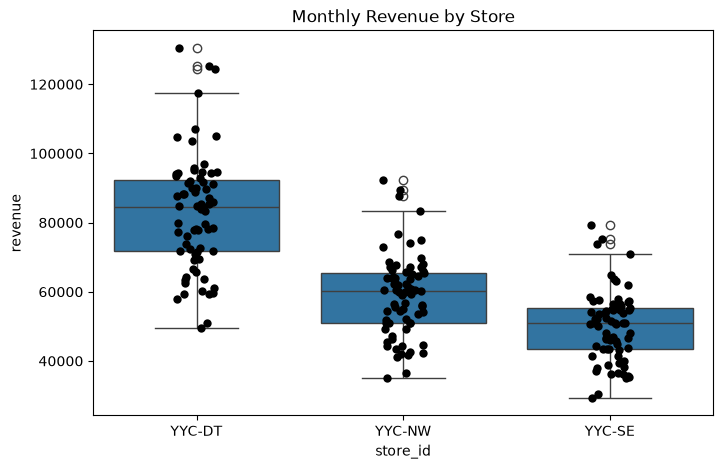

In [7]:
order = ['YYC-DT', 'YYC-NW', 'YYC-SE']

plt.figure(figsize=(8, 5))
sns.boxplot(data=store_monthly, x='store_id', y='revenue', order=order)
sns.stripplot(data=store_monthly, x='store_id', y='revenue', order=order, color='black', size=6, jitter=True)
plt.title('Monthly Revenue by Store')
plt.show()

In [9]:
from scipy.stats import kruskal

dt = store_monthly[store_monthly['store_id'] == 'YYC-DT']['revenue']
nw = store_monthly[store_monthly['store_id'] == 'YYC-NW']['revenue']
se = store_monthly[store_monthly['store_id'] == 'YYC-SE']['revenue']

results = kruskal(dt, nw, se)
print(results)

KruskalResult(statistic=np.float64(115.43207743073333), pvalue=np.float64(8.594940382224459e-26))


In [10]:
import scikit_posthocs as sp

dunn_result = sp.posthoc_dunn(
    store_monthly, 
    val_col='revenue', 
    group_col='store_id', 
    p_adjust='bonferroni'
)
print(dunn_result)

              YYC-DT        YYC-NW        YYC-SE
YYC-DT  1.000000e+00  1.417973e-11  1.118689e-25
YYC-NW  1.417973e-11  1.000000e+00  7.407103e-04
YYC-SE  1.118689e-25  7.407103e-04  1.000000e+00


In [ ]:
store_channel_monthly = (
    sales.groupby([sales['date'].dt.to_period('M'), 'store_id', 'channel'])['revenue']
    .sum()
    .reset_index()
)

store_channel_monthly

,date,store_id,channel,revenue
0,2019-01,YYC-DT,IN_STORE,62488.30
1,2019-01,YYC-DT,ONLINE,6680.42
2,2019-01,YYC-NW,IN_STORE,44549.72
3,2019-01,YYC-NW,ONLINE,4563.04
4,2019-01,YYC-SE,IN_STORE,37746.66
...,...,...,...,...
427,2024-12,YYC-DT,ONLINE,20499.61
428,2024-12,YYC-NW,IN_STORE,77801.31
429,2024-12,YYC-NW,ONLINE,14401.07
430,2024-12,YYC-SE,IN_STORE,67527.89


<Axes: xlabel='store_id'>

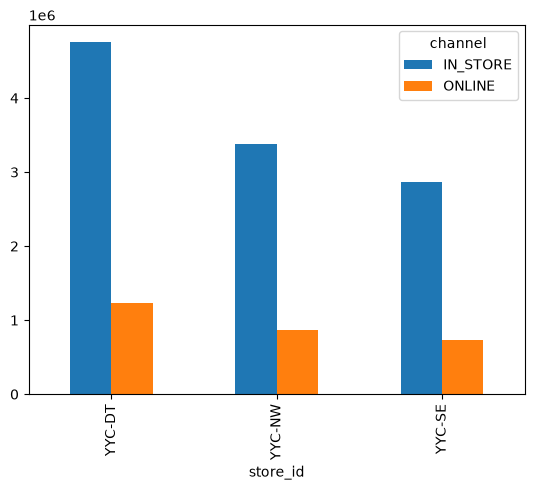

In [16]:
store_channel_total = (
    store_channel_monthly.groupby(['store_id', 'channel'])['revenue']
    .sum()
    .unstack()
)
store_channel_total.plot(kind='bar')

In [17]:
online_share = (store_channel_total['ONLINE'] / store_channel_total.sum(axis=1) * 100).round(1)
print(online_share)

store_id
YYC-DT    20.5
YYC-NW    20.4
YYC-SE    20.2
dtype: float64


## Findings: Which Stores and Channels Drive Revenue?

YYC-DT is the strongest store by a wide margin, with a median monthly revenue
of roughly $85K, against about $60K for YYC-NW and $51K for YYC-SE. A
Kruskal-Wallis test confirms the stores differ (p < 0.001), and Dunn's post-hoc
test shows every pair is significantly different, including NW vs SE
(p = 0.0007). The ranking DT > NW > SE is real, not noise.

To see where DT's lead comes from, I split each store's revenue by channel.
Online made up 20.5% of revenue at DT, 20.4% at NW, and 20.2% at SE. The mix
is essentially the same everywhere, so the stores differ in size, not in how
they sell.

**Bottom line**: DT's lead is not driven by online sales. Both its in-store and
online revenue are larger, in the same proportion as the other stores, which
points to the physical location doing more business. For an expansion decision,
this suggests a new store's results will depend on its location more than on
its online presence.